# Function 5: kernel accuracy, calibration, and historical backtesting

A focused follow-up to Notebook 04. Compare the same five kernels using paired folds, individual out-of-fold predictions, interval widths, historical next-week predictions, and a training-mean baseline. `FUNCTION_ID` can select another function.

This notebook is read-only: no observations, submissions, or saved historical predictions are changed. Shuffled CV measures reconstruction on the available data; historical backtesting tests the actual next evaluated points without future outcomes in the fit.

In [1]:
%matplotlib inline
from pathlib import Path

from IPython.display import display
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.model_selection import KFold

from bayesian_bbo import CONFIG
from bayesian_bbo.history import load_weekly_history
from bayesian_bbo.kernels import make_comparison_kernels
from bayesian_bbo.validation import evaluate_kernel_splits

CURRENT_WEEK = 4
WEEKS = tuple(range(1, CURRENT_WEEK + 1))
FUNCTION_ID = 5
N_SPLITS = 5
RANDOM_STATE = CONFIG['random_state']
N_RESTARTS = CONFIG['n_restarts_optimizer']

data_candidates = [Path('../../data'), Path('data'), Path('../data')]
matches = [path.resolve() for path in data_candidates if (path / 'function_1').is_dir()]
if not matches:
    raise FileNotFoundError('Could not find the data directory from the notebook working directory.')
data_root = matches[0]
history = load_weekly_history(data_root, current_week=CURRENT_WEEK, function_ids=(FUNCTION_ID,))
historical_results = history.records.loc[history.records.week.isin(WEEKS)].copy()
observations = history.observations[FUNCTION_ID]
kernels = make_comparison_kernels(observations.dimension, CONFIG['length_caps'][FUNCTION_ID])
kernel_names = list(kernels) + ['Training mean']
print(f'Function {FUNCTION_ID}: {len(observations.outputs)} observations, {observations.dimension} dimensions')
print(f'Cutoff week {CURRENT_WEEK}; {N_SPLITS} folds; {N_RESTARTS} GP optimizer restarts')
display(historical_results[['week', 'observed_output', 'expected_mean', 'expected_std', 'residual']])

Function 5: 24 observations, 4 dimensions
Cutoff week 4; 5 folds; 10 GP optimizer restarts


,week,observed_output,expected_mean,expected_std,residual
0,1,1397.545109,689.501455,200.322259,3.534523
1,2,1588.598502,1720.386794,71.126598,-1.852869
2,3,3949.359248,1608.846266,24.701896,94.750337
3,4,2060.381950,4093.302693,167.549994,-12.133219


## 1. Shared folds and a simple baseline

All kernels and the baseline use exactly the same training/validation indices. Target normalization is fitted on training rows only. The baseline predicts the training mean; its Gaussian uncertainty uses the population training standard deviation. This is a simple reference, not a calibrated noise model.

Intervals use the returned predictive std. A reported `scoring_std` floor of 1e-9 is used only for numerical stability in standardized errors and predictive NLL. Lower RMSE, MAE, and NLL are better. Coverage must be read together with interval width; wide bands alone do not imply a useful predictor.

In [2]:
folds = dict(enumerate(KFold(n_splits=N_SPLITS, shuffle=True, random_state=RANDOM_STATE).split(observations.inputs), start=1))
oof = evaluate_kernel_splits(
    observations, kernels, folds, random_state=RANDOM_STATE,
    n_restarts_optimizer=N_RESTARTS, normalize_y=CONFIG['normalize_y'],
)
for name, rows in oof.groupby('kernel'):
    assert rows.row_index.nunique() == len(observations.outputs)
    assert len(rows) == len(observations.outputs)
oof['is_best_observation'] = oof.row_index == observations.best_index

def summarize_predictions(frame, groups):
    summary = frame.groupby(groups).agg(
        count=('actual', 'size'), MSE=('squared_error', 'mean'),
        MAE=('absolute_error', 'mean'), NLL=('nlpd', 'mean'),
        coverage_90=('covered_90', 'mean'), coverage_95=('covered_95', 'mean'),
        width_90=('width_90', 'mean'), width_95=('width_95', 'mean'),
        worst_abs_z=('z', lambda values: values.abs().max()),
    )
    summary['RMSE'] = np.sqrt(summary.pop('MSE'))
    return summary

fold_scores = summarize_predictions(oof, ['kernel', 'split'])
oof_summary = summarize_predictions(oof, 'kernel')
oof_summary['RMSE_vs_baseline'] = oof_summary.RMSE / oof_summary.loc['Training mean', 'RMSE']
display(oof_summary.sort_values('RMSE').round(3))
print('Summary pools held-out observations; it is not the unweighted mean of fold RMSEs in Notebook 04.')

/home/pabloncho/repositories/bayesian-bbo/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 0 of parameter k1__k2__length_scale is close to the specified upper bound 100.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
/home/pabloncho/repositories/bayesian-bbo/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 3 of parameter k1__k2__length_scale is close to the specified upper bound 100.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
/home/pabloncho/repositories/bayesian-bbo/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 0 of parameter k1__k2__alpha is close to the specified upper bound 100000.0. Increasing the bound and calling fit again may find a better va

,count,MAE,NLL,coverage_90,coverage_95,width_90,width_95,worst_abs_z,RMSE,RMSE_vs_baseline
kernel,,,,,,,,,,
Matérn 3/2,24,369.046,158.924,0.792,0.833,1201.579,1431.668,84.015,680.900,0.683
Matérn 5/2,24,390.203,149.291,0.708,0.750,1051.056,1252.322,80.698,700.773,0.703
Rational Quadratic,24,430.302,10.353,0.708,0.833,1053.008,1254.648,10.443,709.132,0.711
RBF,24,470.722,172.164,0.625,0.708,1116.101,1329.823,83.983,794.054,0.796
Training mean,24,687.147,10.090,0.875,0.875,2849.640,3395.315,9.157,997.490,1.000
Exp-Sine-Squared,24,764.299,10.204,0.833,0.833,2653.849,3162.033,9.159,1092.682,1.095


Summary pools held-out observations; it is not the unweighted mean of fold RMSEs in Notebook 04.


## 2. Which folds drive the differences?

Inspect the paired fold scores, not just mean +/- fold standard deviation. A negative difference from Matérn 3/2 favors the alternative. Shared folds have overlapping training data, so these are descriptive comparisons, not independent replicates or significance tests.

The fold containing the best observed output is flagged. Its difficulty may explain a large average error or NLL, but check individual predictions below before attributing the failure to that observation.

,fold,validation_rows,largest_validation_output,contains_best
0,1,"[0, 8, 11, 16, 18]",431.612757,False
1,2,"[1, 5, 9, 13, 21]",1588.598502,False
2,3,"[2, 3, 4, 12, 15]",1088.859618,False
3,4,"[7, 17, 20, 22, 23]",3949.359248,True
4,5,"[6, 10, 14, 19]",355.806818,False


RMSE       MAE      NLL  coverage_95  width_95
kernel             split                                                    
Exp-Sine-Squared   1       506.662   481.579    7.953          1.0  3910.848
                   2      1113.459   854.932    8.491          0.8  2675.715
                   3       580.538   555.283    8.002          1.0  3932.713
                   4      1925.381  1403.451   18.192          0.4  1589.913
                   5       487.813   466.734    7.929          1.0  3835.710
Matérn 3/2         1       117.989   115.514    7.170          1.0  1980.997
                   2       393.831   325.272    7.377          1.0  1863.527
                   3        89.086    85.187    6.947          1.0  1644.246
                   4      1351.255   884.440  734.737          0.6   243.906
                   5       527.432   451.262    8.255          0.5  1424.166
Matérn 5/2         1       186.685   184.885    7.159          1.0  1871.620
                   2       476.934   340.077    7.616          0.8  1460.728
                   3       106.117    94.202    6.924          1.0  1487.732
                   4      1360.267   888.382  687.818          0.4   203.472
                   5       540.013   456.787    8.852          0.5  1234.493
RBF                1       185.113   141.771    7.317          1.0  2236.645
                   2       864.848   616.635   39.687          0.6  1021.068
                   3       352.557   276.993    7.415          1.0  1950.132
                   4      1376.389   902.908  764.189          0.4   160.606
                   5       530.955   401.446    9.724          0.5  1268.373
Rational Quadratic 1       420.404   372.008    7.495          1.0  1439.760
                   2       576.837   453.158    9.038          0.6  1155.778
                   3       160.443   142.308    7.051          1.0  1674.102
                   4      1326.516   849.541   20.128          0.6   710.569
                   5       385.522   310.545    7.476          1.0  1302.627
Training mean      1       506.662   481.579    7.953          1.0  3911.730
                   2       612.210   552.299    7.999          1.0  3826.548
                   3       496.928   487.473    7.946          1.0  3899.944
                   4      1925.388  1403.567   18.188          0.4  1590.234
                   5       487.813   466.734    7.929          1.0  3836.321

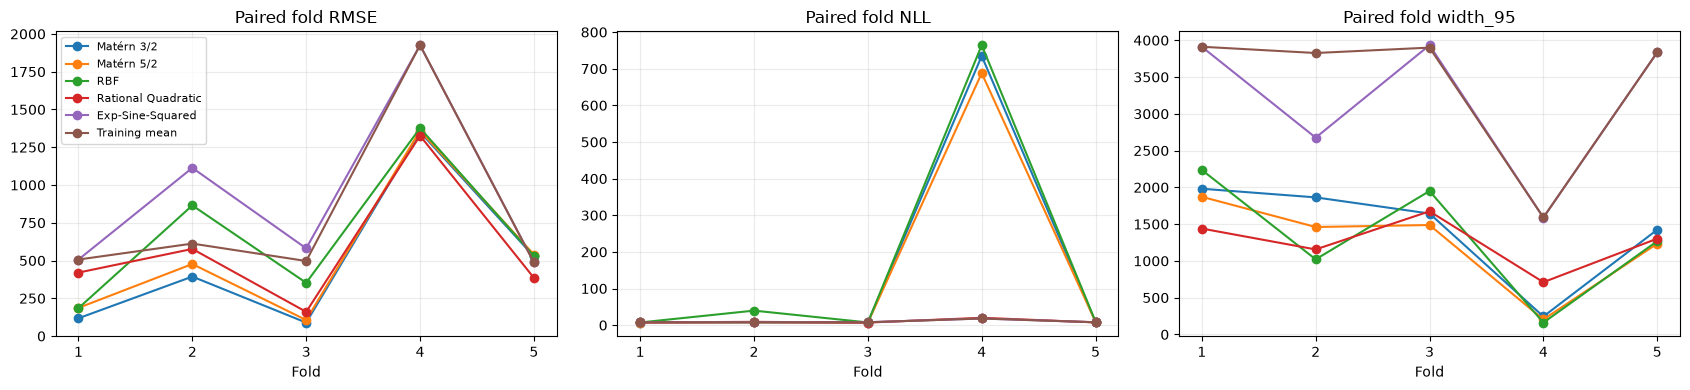

kernel        Exp-Sine-Squared  Matérn 3/2  Matérn 5/2      RBF  \
metric split                                                      
RMSE   1               388.672         0.0      68.695   67.123   
       2               719.628         0.0      83.103  471.017   
       3               491.452         0.0      17.032  263.471   
       4               574.126         0.0       9.012   25.134   
       5               -39.619         0.0      12.581    3.523   
NLL    1                 0.784         0.0      -0.011    0.148   
       2                 1.113         0.0       0.239   32.310   
       3                 1.055         0.0      -0.023    0.468   
       4              -716.545         0.0     -46.919   29.452   
       5                -0.326         0.0       0.597    1.469   

kernel        Rational Quadratic  Training mean  
metric split                                     
RMSE   1                 302.415        388.672  
       2                 183.006        218.379  
       3                  71.357        407.842  
       4                 -24.739        574.134  
       5                -141.910        -39.619  
NLL    1                   0.326          0.784  
       2                   1.661          0.622  
       3                   0.104          0.999  
       4                -714.609       -716.549  
       5                  -0.779         -0.326

In [3]:
fold_membership = pd.DataFrame([
    {'fold': number, 'validation_rows': test.tolist(),
     'largest_validation_output': observations.outputs[test].max(),
     'contains_best': observations.best_index in test}
    for number, (_, test) in folds.items()
])
display(fold_membership)
display(fold_scores[['RMSE', 'MAE', 'NLL', 'coverage_95', 'width_95']].round(3))
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
for ax, metric in zip(axes, ['RMSE', 'NLL', 'width_95']):
    table = fold_scores[metric].unstack('kernel')
    for name in kernel_names:
        ax.plot(table.index, table[name], marker='o', label=name)
    ax.set(title=f'Paired fold {metric}', xlabel='Fold', xticks=list(folds))
    ax.grid(alpha=0.25)
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()
paired_differences = pd.concat({
    metric: fold_scores[metric].unstack('kernel').subtract(
        fold_scores[metric].xs('Matérn 3/2', level='kernel'), axis=0,
    ) for metric in ['RMSE', 'NLL']
}, names=['metric', 'split'])
display(paired_differences.round(3))

## 3. Individual held-out predictions and high-output failures

Each panel orders observations by actual output. Black markers are actual values; colored markers and error bars show held-out predictions and nominal 95% intervals. Red crosses mark misses. The orange vertical line identifies the best observation. Rows in the detail tables retain the original observation index and recording week.

The worst-NLL table identifies the exact observations driving probabilistic failures. The high-output table covers the five largest observed values; selecting these for diagnosis is retrospective, not a leakage-free way to tune the model.

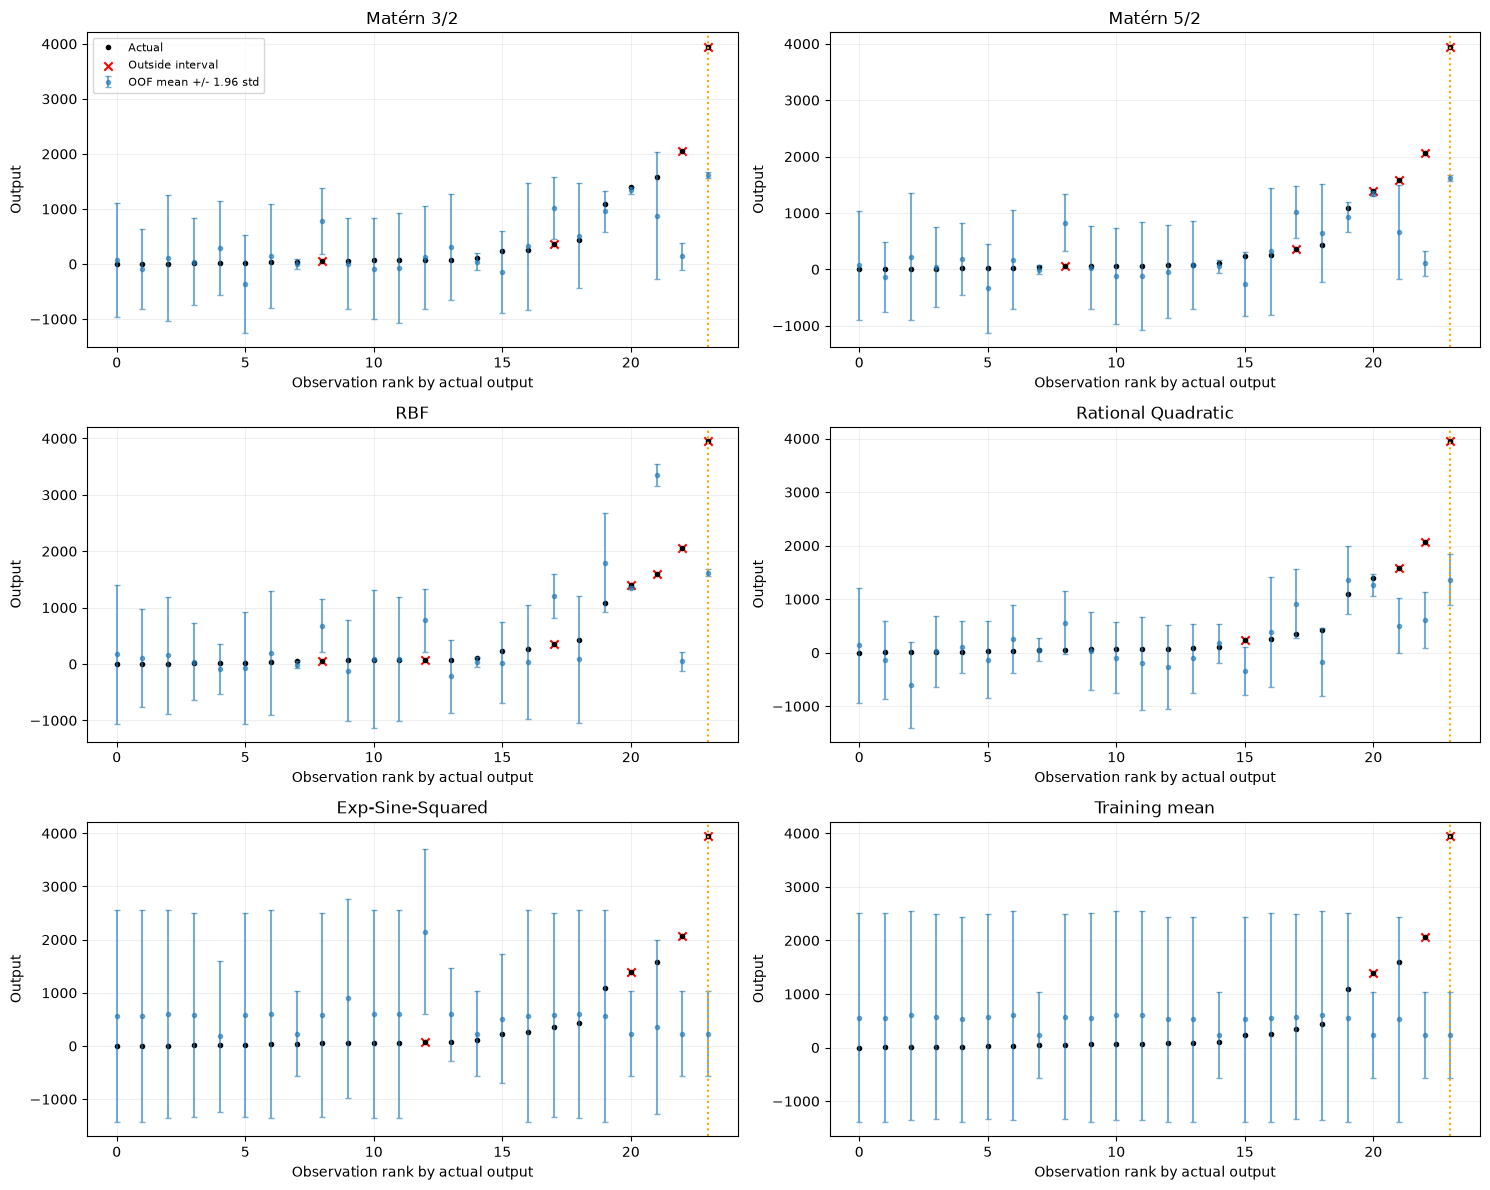

,kernel,split,row_index,week,actual,mean,std,z,nlpd,covered_95
98,Matérn 3/2,4,22,3,3949.359,1615.084,27.784,84.015,3533.474,False
108,RBF,4,22,3,3949.359,1622.398,27.707,83.983,3530.823,False
103,Matérn 5/2,4,22,3,3949.359,1619.527,28.871,80.698,3260.327,False
109,RBF,4,23,4,2060.382,48.701,87.690,22.941,268.531,False
104,Matérn 5/2,4,23,4,2060.382,107.157,110.979,17.600,160.508,False
99,Matérn 3/2,4,23,4,2060.382,144.528,125.059,15.320,123.092,False
113,Rational Quadratic,4,22,3,3949.359,1366.855,247.305,10.443,60.953,False
118,Exp-Sine-Squared,4,22,3,3949.359,234.699,405.591,9.159,48.865,False
93,Training mean,4,22,3,3949.359,234.699,405.672,9.157,48.848,False
114,Rational Quadratic,4,23,4,2060.382,609.281,265.357,5.468,21.452,False


,kernel,split,row_index,week,actual,mean,std,z,nlpd,covered_95
118,Exp-Sine-Squared,4,22,3,3949.359,234.699,405.591,9.159,48.865,False
98,Matérn 3/2,4,22,3,3949.359,1615.084,27.784,84.015,3533.474,False
103,Matérn 5/2,4,22,3,3949.359,1619.527,28.871,80.698,3260.327,False
108,RBF,4,22,3,3949.359,1622.398,27.707,83.983,3530.823,False
113,Rational Quadratic,4,22,3,3949.359,1366.855,247.305,10.443,60.953,False
93,Training mean,4,22,3,3949.359,234.699,405.672,9.157,48.848,False
119,Exp-Sine-Squared,4,23,4,2060.382,234.699,405.591,4.501,17.055,False
99,Matérn 3/2,4,23,4,2060.382,144.528,125.059,15.320,123.092,False
104,Matérn 5/2,4,23,4,2060.382,107.157,110.979,17.600,160.508,False
109,RBF,4,23,4,2060.382,48.701,87.690,22.941,268.531,False


In [4]:
output_order = np.argsort(observations.outputs)
fig, axes = plt.subplots(3, 2, figsize=(15, 12), squeeze=False)
for name, ax in zip(kernel_names, axes.ravel()):
    rows = oof.loc[oof.kernel == name].set_index('row_index').loc[output_order]
    positions = np.arange(len(rows))
    ax.plot(positions, rows.actual, 'k.', label='Actual')
    ax.errorbar(positions, rows['mean'], yerr=1.96 * rows['std'], fmt='o', markersize=3,
                alpha=0.6, capsize=2, label='OOF mean +/- 1.96 std')
    misses = ~rows.covered_95.to_numpy()
    ax.scatter(positions[misses], rows.actual.to_numpy()[misses], color='red', marker='x', label='Outside interval')
    ax.axvline(int(np.flatnonzero(output_order == observations.best_index)[0]), color='orange', linestyle=':')
    ax.set(title=name, xlabel='Observation rank by actual output', ylabel='Output')
    ax.grid(alpha=0.2)
axes[0, 0].legend(fontsize=8)
plt.tight_layout()
plt.show()
detail_columns = ['kernel', 'split', 'row_index', 'week', 'actual', 'mean', 'std', 'z', 'nlpd', 'covered_95']
worst_points = oof.sort_values('nlpd', ascending=False).groupby('kernel', sort=False).head(2)
display(worst_points[detail_columns].round(3))
top_indices = output_order[-min(5, len(output_order)):]
display(oof.loc[oof.row_index.isin(top_indices), detail_columns].sort_values(['actual', 'kernel'], ascending=[False, True]).round(3))

## 4. Coverage versus sharpness

Read coverage and width together with the accuracy/NLL table. A desirable model has accurate means and useful intervals, not merely high coverage from enormous bands. The nominal 95% line is a reference, not evidence that a model is calibrated from only 24 observations.

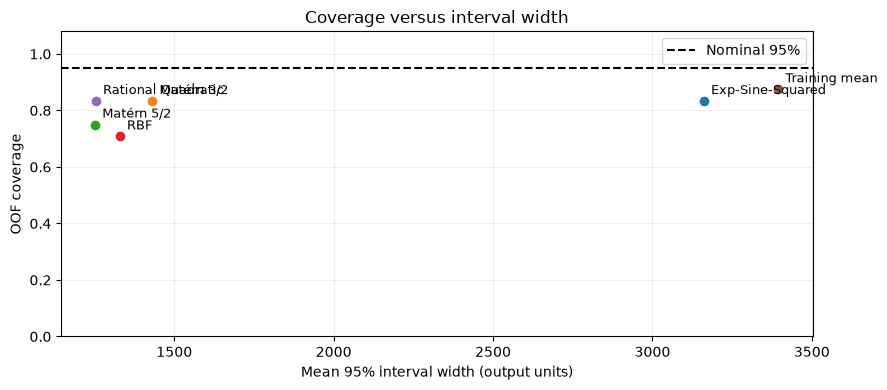

In [5]:
fig, ax = plt.subplots(figsize=(9, 4))
for name, row in oof_summary.iterrows():
    ax.scatter(row.width_95, row.coverage_95)
    ax.annotate(name, (row.width_95, row.coverage_95), xytext=(5, 5), textcoords='offset points', fontsize=9)
ax.axhline(0.95, color='black', linestyle='--', label='Nominal 95%')
ax.set(xlabel='Mean 95% interval width (output units)', ylabel='OOF coverage', title='Coverage versus interval width', ylim=(0, 1.08))
ax.legend()
ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

## 5. Historical next-week prediction tests

For week w, train only on rows recorded before w and predict that week's actual evaluated input. The same rule applies to the baseline. These fits evaluate current candidate kernel specifications retrospectively; they do not claim to reproduce every historical optimizer setting. The actual historical GP prediction is shown separately for reference.

The four inputs were selected by earlier policies, not by these alternative kernels. This tests predictive behavior at those inputs, not which alternative policy would have found the best optimum. Four outcomes are too few to estimate reliable coverage or pick a winner confidently.

/home/pabloncho/repositories/bayesian-bbo/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 0 of parameter k1__k2__length_scale is close to the specified upper bound 100.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
/home/pabloncho/repositories/bayesian-bbo/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 0 of parameter k1__k2__length_scale is close to the specified upper bound 100.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
/home/pabloncho/repositories/bayesian-bbo/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 1e-08. Decreasing the bound and calling fit again may find a better val

,count,MAE,NLL,coverage_90,coverage_95,width_90,width_95,worst_abs_z,RMSE
kernel,,,,,,,,,
Exp-Sine-Squared,4,1981.629,20.683,0.00,0.25,1585.995,1889.696,8.132,2214.168
Training mean,4,1981.914,20.760,0.00,0.25,1583.904,1887.205,8.130,2214.378
Rational Quadratic,4,784.068,25.553,0.50,0.50,823.999,981.786,11.877,1185.654
RBF,4,1393.338,382.116,0.00,0.00,356.033,424.210,53.086,1636.345
Matérn 5/2,4,1149.928,943.990,0.25,0.25,258.039,307.451,85.805,1559.690
Matérn 3/2,4,1148.969,1146.364,0.25,0.50,278.063,331.310,94.750,1552.124


,kernel,week,training_count,actual,mean,std,lower_95,upper_95,z,nlpd,covered_95
0,Training mean,1,20,1397.545,151.272,245.576,-330.057,632.601,5.075,19.300,False
1,Matérn 3/2,1,20,1397.545,1306.889,74.693,1160.492,1453.287,1.214,5.969,True
2,Matérn 5/2,1,20,1397.545,1347.084,64.327,1221.003,1473.165,0.784,5.391,True
3,RBF,1,20,1397.545,402.701,175.960,57.819,747.583,5.654,22.072,False
4,Rational Quadratic,1,20,1397.545,1111.536,85.783,943.401,1279.670,3.334,10.929,False
5,Exp-Sine-Squared,1,20,1397.545,151.272,248.840,-336.455,638.999,5.008,18.977,False
6,Training mean,2,21,1588.599,210.618,357.597,-490.272,911.508,3.853,14.223,False
7,Matérn 3/2,2,21,1588.599,1720.387,71.127,1580.979,1859.795,-1.853,6.900,True
8,Matérn 5/2,2,21,1588.599,1741.294,46.968,1649.237,1833.351,-3.251,10.053,False
9,RBF,2,21,1588.599,1772.143,31.831,1709.754,1834.532,-5.766,21.004,False


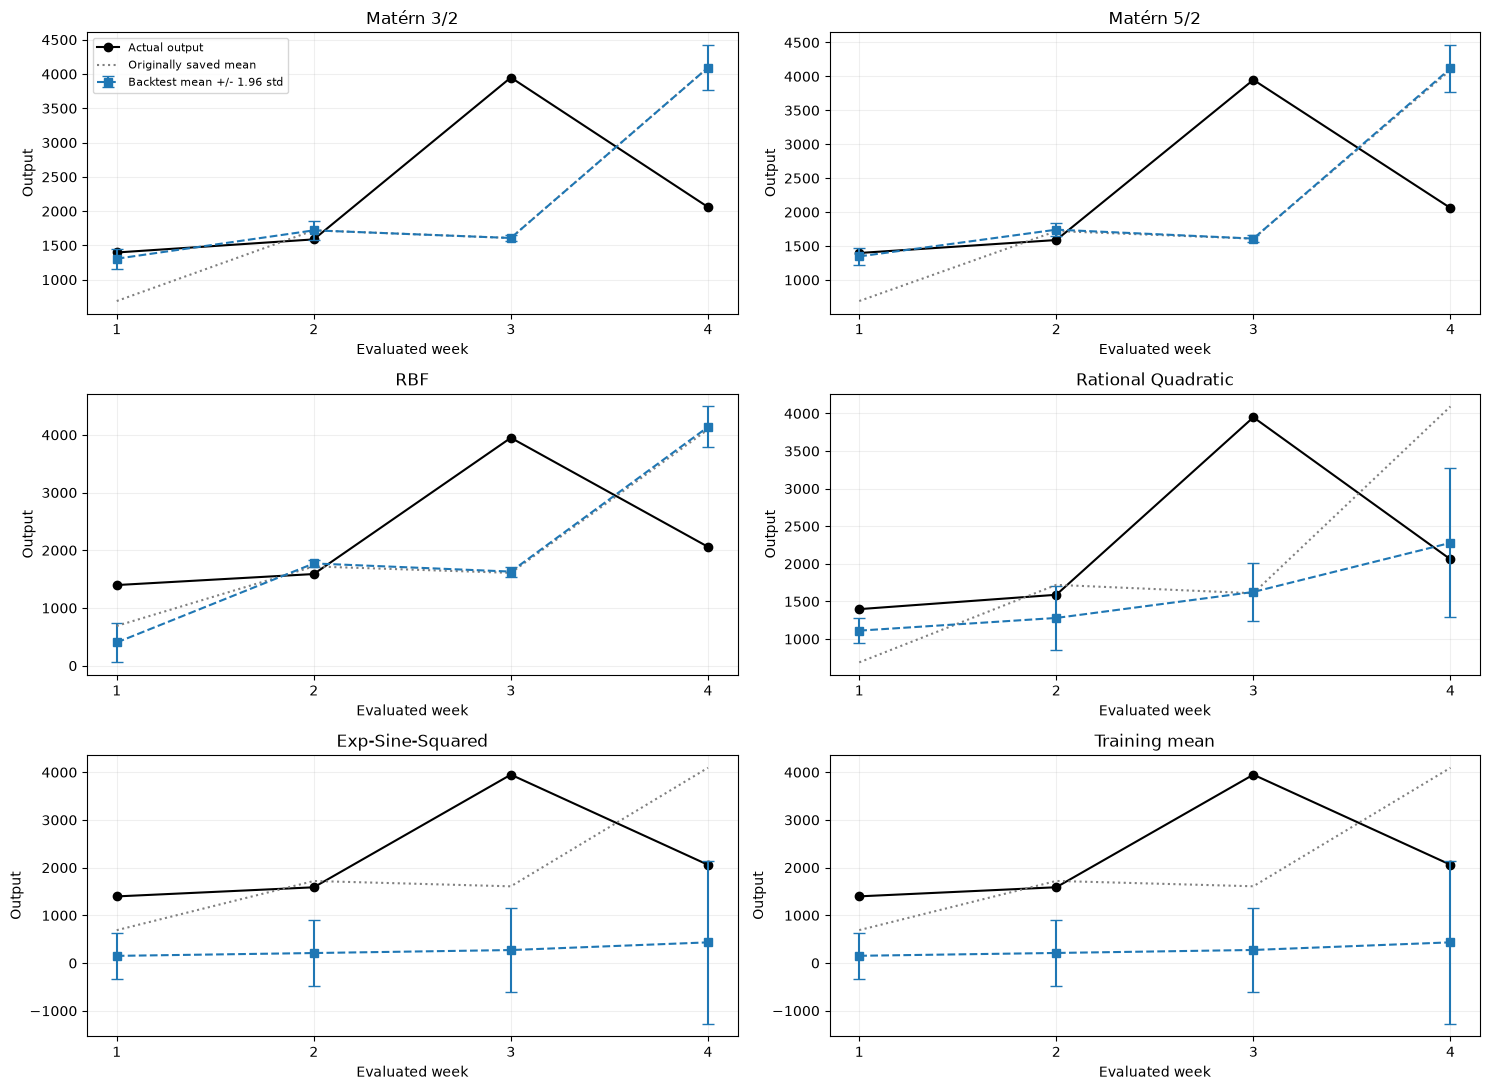

In [6]:
historical_splits = {
    week: (np.flatnonzero(observations.weeks < week), np.flatnonzero(observations.weeks == week))
    for week in WEEKS
}
backtest = evaluate_kernel_splits(
    observations, kernels, historical_splits, random_state=RANDOM_STATE,
    n_restarts_optimizer=N_RESTARTS, normalize_y=CONFIG['normalize_y'],
)
assert (backtest.training_max_week < backtest.week).all()
assert (backtest['split'] == backtest.week).all()
backtest_summary = summarize_predictions(backtest, 'kernel')
display(backtest_summary.sort_values('NLL').round(3))
display(backtest[['kernel', 'week', 'training_count', 'actual', 'mean', 'std', 'lower_95', 'upper_95', 'z', 'nlpd', 'covered_95']].round(3))
fig, axes = plt.subplots(3, 2, figsize=(15, 11), squeeze=False)
for name, ax in zip(kernel_names, axes.ravel()):
    rows = backtest.loc[backtest.kernel == name].sort_values('week')
    ax.plot(rows.week, rows.actual, 'k-o', label='Actual output')
    ax.errorbar(rows.week, rows['mean'], yerr=1.96 * rows['std'], fmt='s--', capsize=4, label='Backtest mean +/- 1.96 std')
    ax.plot(historical_results.week, historical_results.expected_mean, ':', color='gray', label='Originally saved mean')
    ax.set(title=name, xlabel='Evaluated week', ylabel='Output', xticks=list(WEEKS))
    ax.grid(alpha=0.2)
axes[0, 0].legend(fontsize=8)
plt.tight_layout()
plt.show()

## 6. Decision aid, not automatic kernel selection

Compare accuracy and probabilistic scores on both evaluation designs. A negative paired NLL difference favors the alternative; an RMSE ratio below one beats the baseline. Inspect high-output misses, interval widths, and fitted-kernel warnings before adopting a model. NLL values are comparable within this function and output scale, not directly across functions.

No automatic ranking threshold or export is applied. Candidate-quality testing, repeated splits, and more sequential outcomes are needed before changing the optimization policy. Convergence warnings remain visible; a boundary fit or negative-variance warning warrants investigation rather than being treated as successful calibration.

In [7]:
decision_table = oof_summary[['RMSE', 'MAE', 'NLL', 'coverage_95', 'width_95', 'RMSE_vs_baseline']].add_prefix('OOF_').join(
    backtest_summary[['RMSE', 'MAE', 'NLL', 'coverage_95', 'width_95']].add_prefix('Historical_')
)
display(decision_table.sort_values('OOF_RMSE').round(3))
print('Lowest pooled OOF RMSE:', oof_summary.RMSE.idxmin())
print('Lowest pooled OOF NLL:', oof_summary.NLL.idxmin())
print('Lowest historical NLL:', backtest_summary.NLL.idxmin())
print('These descriptive winners are not evidence of a robust best kernel or future optimization success.')

,OOF_RMSE,OOF_MAE,OOF_NLL,OOF_coverage_95,OOF_width_95,OOF_RMSE_vs_baseline,Historical_RMSE,Historical_MAE,Historical_NLL,Historical_coverage_95,Historical_width_95
kernel,,,,,,,,,,,
Matérn 3/2,680.900,369.046,158.924,0.833,1431.668,0.683,1552.124,1148.969,1146.364,0.50,331.310
Matérn 5/2,700.773,390.203,149.291,0.750,1252.322,0.703,1559.690,1149.928,943.990,0.25,307.451
Rational Quadratic,709.132,430.302,10.353,0.833,1254.648,0.711,1185.654,784.068,25.553,0.50,981.786
RBF,794.054,470.722,172.164,0.708,1329.823,0.796,1636.345,1393.338,382.116,0.00,424.210
Training mean,997.490,687.147,10.090,0.875,3395.315,1.000,2214.378,1981.914,20.760,0.25,1887.205
Exp-Sine-Squared,1092.682,764.299,10.204,0.833,3162.033,1.095,2214.168,1981.629,20.683,0.25,1889.696


Lowest pooled OOF RMSE: Matérn 3/2
Lowest pooled OOF NLL: Training mean
Lowest historical NLL: Exp-Sine-Squared
These descriptive winners are not evidence of a robust best kernel or future optimization success.
